In [2]:
import numpy as np
import matplotlib.pyplot as plt

import cnetwork
from cnetwork import MagmaChamber, GlobalSystemThreshold

In [167]:
# Set reference density of melt
rhoref = 2500
# Set limits of characteristic size of chamber
R_ref = 100
# Uniformly randomly distribution volume
V_ref = (4/3)*np.pi*R_ref**3

# Generate list of chambers
x_nodes = np.array([-2000,  4000,  0    ])
y_nodes = np.array([-0,     0,     0    ])
z_nodes = np.array([-6000,  -4000, -1000])
V_nodes = np.array([4.0,    0.25,  1 ]) * V_ref
list_nodes = [MagmaChamber(x=x, y=y, z=z,
  p_setting=None, vref=1.0/rhoref,
  T_setting=1000+273.15, V_setting=V)
  for (x,y,z,V) in zip(x_nodes, y_nodes, z_nodes, V_nodes)]

In [168]:
# Set up system with default properties
global_sys = GlobalSystemThreshold(list_nodes,
  **cnetwork.default_props(),
  **cnetwork.default_numerics(),
  dpdx_crit=1e3, dpdx_threshold_scale=1e2, max_edge_dist=np.inf)

# Source term due to eruption at node -1
f_erupt = global_sys.create_eruptible_layer(
  p_erupt_min=5e6, p_erupt_max=5e6,
  z_min=-1200, z_max=0.0, mu_erupt=1e5, r_conduit=25)

# Define multiple injections
# mdot_inj1 = 0.3 # SET 1
# mdot_inj2 = 0.6 # SET 1
mdot_inj1 = 5e-10 * V_ref * rhoref
mdot_inj2 = 5e-10 * V_ref * rhoref

def f_inj_multiple(t, q):
  ''' Constant mass rate injection at node indices 0 and 1. '''
  f_inj = np.zeros((global_sys.num_dof))
  f_inj[global_sys.data_slice_global(0, "mass")] = mdot_inj1
  f_inj[global_sys.data_slice_global(1, "mass")] = mdot_inj2
  return f_inj

In [169]:
t_vec = np.linspace(0, 50e7, 25000)
q_out, m_erupted_out = global_sys.simulation(global_sys.q0, t_vec, f_inj_multiple, f_erupt)
m, p, u = global_sys.compute_m_p_u(q_out)

In [170]:
Y_all = global_sys.compute_time_averaged_connectivity_matrix(
  t_vec, q_out, averaged=False)

Preview plot for checking simulation data:


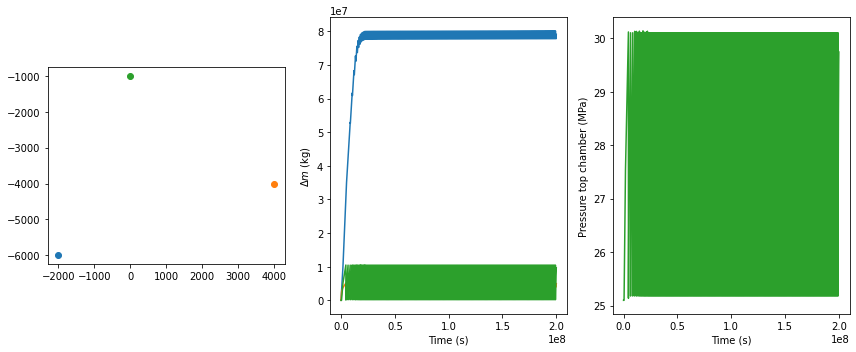

In [318]:
plt.figure(figsize=(12,5))

plt.subplot(1,3,1)
color_cycle = plt.rcParams["axes.prop_cycle"].by_key()["color"]
N_chambers = len(x_nodes)
for i in range(N_chambers):
  plt.scatter(x_nodes[i], z_nodes[i], c=color_cycle[i])
plt.gca().set_aspect('equal')

plt.subplot(1,3,2)
plot_idx = 10000
plt.plot(t_vec[:plot_idx], m[:,0][:plot_idx] - m[:,0][0])
plt.plot(t_vec[:plot_idx], m[:,1][:plot_idx] - m[:,1][0])
plt.plot(t_vec[:plot_idx], m[:,2][:plot_idx] - m[:,2][0])
plt.xlabel("Time (s)")
plt.ylabel("$\Delta m$ (kg)")

plt.subplot(1,3,3)
plt.plot(t_vec[:plot_idx], p[:,2][:plot_idx] / 1e6, color=color_cycle[2])
plt.xlabel("Time (s)")
plt.ylabel("Pressure top chamber (MPa)")
plt.tight_layout()

print("Preview plot for checking simulation data:")

In [ ]:
# Compute edge-wise masses
mass_rates = np.array([global_sys.mass_rates(q_out[i,:], return_format=None)
                       for i in range(t_vec.size)])

# Extract mass rates
mrates10 = -(mass_rates)[:,1,0]
mrates02 = (mass_rates)[:,2,0]
mrates12 = (mass_rates)[:,2,1]

In [ ]:
# Prep graph-related data for plotting
Y_avg = Y_all.mean(axis=0)
length_scale = 1e3
pos = {i:(n.x / length_scale, n.z / length_scale,)
        for (i, n) in enumerate(global_sys.nodes)}
G = nx.Graph(Y_avg)

Text(0, 0.5, 'Time of occurence (s)')

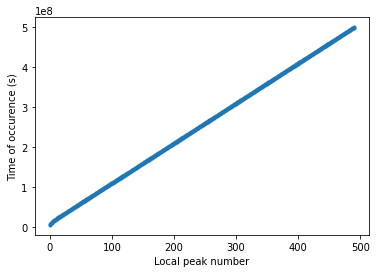

In [ ]:
''' Eruption peak picking '''
# Take data series
series = p[:,2][:] / 1e6

# Compute boolean values corresponding to sign changes
is_peak = (np.diff(series[1:]) > 0).astype(float) * (np.diff(series[:-1]) < 0).astype(float)
# First time data is over 99% of the max
first_index = np.argmax(series > 0.99 * series.max())
# Compute indices where peak is detected in data series
peak_indices = (first_index + 1 + np.where(is_peak[first_index:])).squeeze()
plt.plot(t_vec[peak_indices], '.')
plt.xlabel("Local peak number")
plt.ylabel("Time of occurence (s)")

Lagrangian particle simulation

In [320]:
N_particles_per_node = 1000
n_nodes = len(global_sys.nodes)
N_particles = N_particles_per_node * n_nodes

import scipy
import scipy.sparse
inverse_mass = scipy.sparse.diags([1/node.m0 for node in global_sys.nodes])

start_node = np.full((N_particles,), 0, dtype=int)
for i in range(n_nodes):
  start_node[i*N_particles_per_node:(i+1)*N_particles_per_node] = i
curr_node = start_node.copy()
# Allocate node location history for each particle
node_location = np.full((t_vec.size, N_particles), -1, dtype=int) 
# Fill initial
node_location[0,:] = 0

NTMAX = 60000

avg_turnover_rates = np.zeros((n_nodes+1, n_nodes+1))
num_steps_taken = 0

for i, t in enumerate(t_vec[1:NTMAX]):
  # Load q, pressure from ODE solution
  q = q_out[i,...]

  p_node = global_sys.pressure(q)

  # Compute turnover rates (mdot / m) with virtual node for erupted
  turnover_rates = np.zeros((n_nodes+1, n_nodes+1))
  turnover_rates[:n_nodes, :n_nodes] = inverse_mass @ global_sys.mass_rates(q)
  # Eruption from last node
  turnover_rates[n_nodes, n_nodes-1] = \
    (m_erupted_out[i] - m_erupted_out[i-1]) / global_sys.nodes[-1].m0 / (t_vec[i] - t_vec[i-1])
  # Compute instantaneous Poisson rates from total out rate from node j
  poisson_lambda = np.array(turnover_rates.sum(axis=0)).squeeze()
  # Probability of escaping from node j to node i given that particle escapes
  path_probability = np.zeros(turnover_rates.shape)
  np.divide(turnover_rates, poisson_lambda, where=poisson_lambda!=0, out=path_probability)
  # Probability of exiting in current timestep
  prob = poisson_lambda[curr_node] * (t_vec[i] - t_vec[i-1])

  # Record path probabilities
  avg_turnover_rates += turnover_rates
  num_steps_taken += 1

  # # End walk at last node
  # prob[-1] = 0

  # Determine whether each particle exits node
  exit_roll = np.random.rand(N_particles) < prob
  # Choose exit path based on probability
  new_node = (np.random.rand(N_particles)[np.newaxis,:]
              < np.cumsum(path_probability[:,curr_node], axis=0)).argmax(axis=0)
  # Move all particles
  curr_node = np.where(exit_roll, new_node, curr_node)
  # Save particle location
  node_location[i+1,:] = curr_node

avg_turnover_rates /= num_steps_taken

In [359]:
# Vector representing location at timestep
chamber2_contents = np.zeros((t_vec.size, n_nodes+1))
for k, t in enumerate(t_vec):
  current_loc = node_location[k,:]
  # Vector representing origin of corresponding particle
  origin = np.tile(np.arange(n_nodes), (N_particles_per_node,1)).T.ravel()

  # Matrix tabulating contents of each node
  # Each row i is a chamber, containing count of particles originating from j
  contents = np.zeros((n_nodes+1, n_nodes+1))
  contents[current_loc, origin] += 1
  for (i, j) in zip(current_loc, origin):
    contents[i,j] += 1
  
  chamber2_contents[k,:] = contents[2,:]

In [374]:
# Vector representing location at timestep
chamber2_contents = np.zeros((t_vec.size, n_nodes+1))
for k, t in enumerate(t_vec):
  current_loc = node_location[k,:]
  # Vector representing origin of corresponding particle
  origin = np.tile(np.arange(n_nodes), (N_particles_per_node,1)).T.ravel()

  # Matrix tabulating contents of each node
  # Each row i is a chamber, containing count of particles originating from j
  contents = np.zeros((n_nodes+1, n_nodes+1))
  contents[current_loc, origin] += 1
  for (i, j) in zip(current_loc, origin):
    contents[i,j] += 1
  
  chamber2_contents[k,:] = contents[2,:]

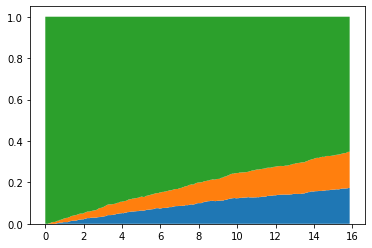

In [375]:
# Compute area chart data
area_x = t_vec[1:] / seconds_per_year
area_y = chamber2_contents[1:,0:3] / chamber2_contents[1:,:].sum(axis=1, keepdims=True)
area_y.shape
plt.stackplot(area_x, area_y.T)

### Make Figure

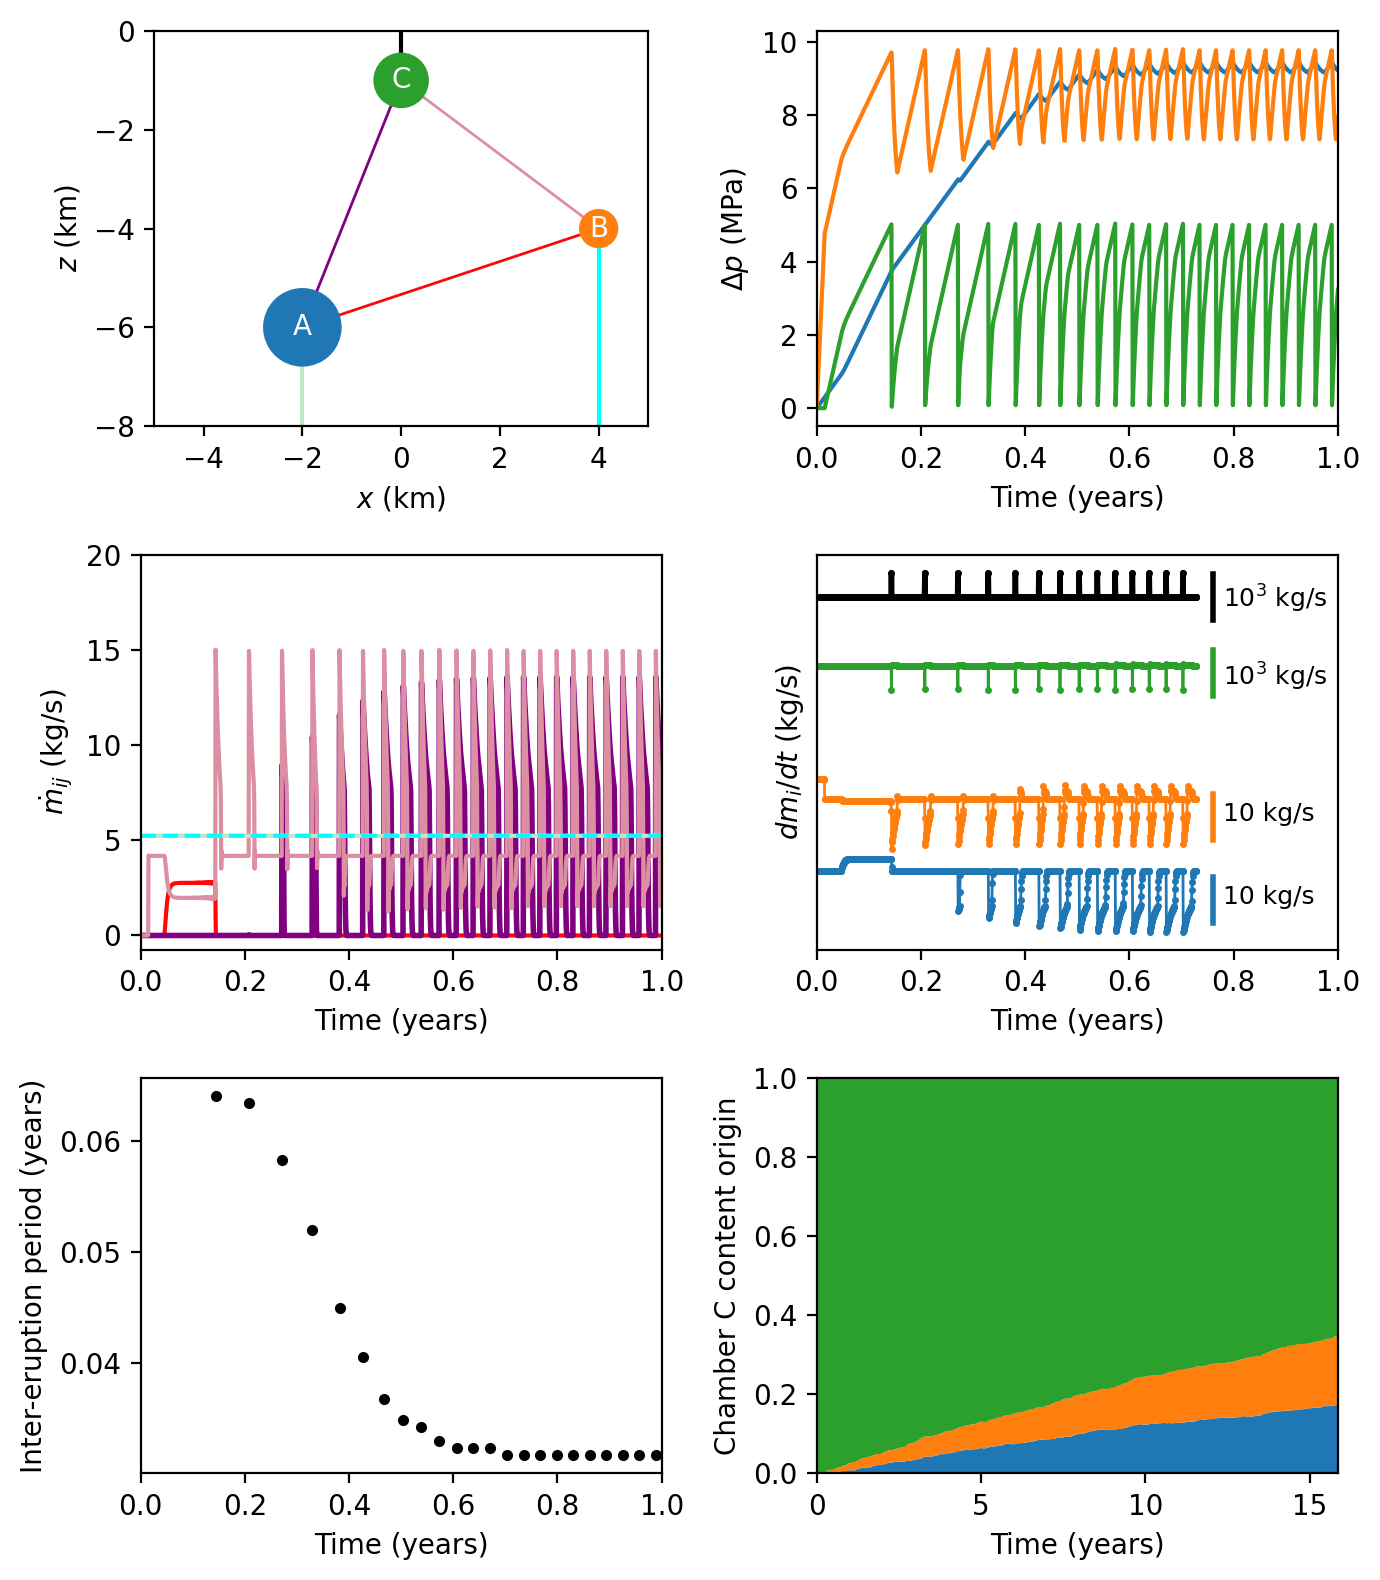

In [ ]:
fig, axes = plt.subplots(3, 2, figsize=(7, 8), dpi=200)
ax_net = axes[0,0]
ax_pressure = axes[0,1]
ax_m_edge = axes[1,0]
ax_m_node = axes[1,1]
ax_period = axes[2,0]
ax_lagrangian = axes[2,1]

import matplotlib.pyplot as plt
import networkx as nx
import matplotlib
seconds_per_year = 365 * 24 * 3600
default_colors = plt.rcParams["axes.prop_cycle"].by_key()["color"]

node_colors = default_colors[:3]
edge_colors = np.array([
  [255,8,8,255],
  [128,0,128,255],
  [220,142,163,255],
  [193,230,195,255],    # Injection edge 1
  [0,255,255,255],  # Injection edge 2
]) / 255.0
nx.draw_networkx_nodes(G, pos,
  node_size=np.sqrt(V_nodes / V_nodes.max())*800,
  node_color=node_colors,
  linewidths=0.0,
  ax=ax_net,
)
nx.draw_networkx_labels(G, pos,
                        labels={
                          0: "A",
                          1: "B", 
                          2: "C",},
  font_size=10,
  font_family="sans-serif",
  font_color="white",
  ax=ax_net)

nx.draw_networkx_edges(G, pos,
  # node_color=edge_colors[:3],
  # node_size=np.sqrt(V_nodes / V_nodes.max())*300,
  edge_color=edge_colors[:3],
  ax=ax_net,
)

# Manual plotting injection edges
ax_net.plot(np.full(2, x_nodes[0]/1e3),
            [-10, z_nodes[0]/1e3],
            c=edge_colors[3], zorder=-1)
ax_net.plot(np.full(2, x_nodes[1]/1e3),
            [-10, z_nodes[1]/1e3], c=edge_colors[4], zorder=-1)
ax_net.plot([0,0], [z_nodes[2]/1e3,1.0], 'k', zorder=-1)

ax_net.tick_params(left=True, bottom=True, labelleft=True, labelbottom=True)
ax_net.set_xlim(-5, 5)
ax_net.set_ylim(-8, 0)
ax_net.set_xlabel("$x$ (km)")
ax_net.set_ylabel("$z$ (km)")
ax_net.set_aspect("equal")

''' Pressure in nodes '''

for i in range(3):
  ax_pressure.plot(t_vec[:plot_idx] / seconds_per_year, (p[:,i] - p[0,i])[:plot_idx] / 1e6, color=color_cycle[i])
ax_pressure.set_xlabel("Time (years)")
ax_pressure.set_ylabel("$\Delta p$ (MPa)")
ax_pressure.set_xlim(0, 1)

''' Mass transfer in nodes '''

# Alias variable m
m_hist = m
isort = np.argsort(z_nodes)
depth_colors = matplotlib.cm.plasma((z_nodes - z_nodes.min()) / (z_nodes.max() - z_nodes.min()))

# irange = np.arange(9480, 9850) # Prod 60000x4 resolution
irange = np.arange(0, 1150)
plot_scaling = 10e-2
y_scalings = [10, 10, 0.1]
erupt_scaling = 1e-1
for n in [0, 1, 2]:
  ax_m_node.plot(t_vec[irange[:-1]] / seconds_per_year,
          y_scalings[n] * np.diff(m_hist[irange,n])/(t_vec[1] - t_vec[0]) + plot_scaling * z_nodes[n],
          '.-',
          c=node_colors[n], linewidth=1, markersize=3)
ax_m_node.plot(t_vec[irange[:-1]] / seconds_per_year,
          erupt_scaling * np.diff(m_erupted_out[irange])/(t_vec[1] - t_vec[0])
            + -0.5*plot_scaling * z_nodes[n], '.-',
          c='k', zorder=-1, linewidth=2, markersize=3)

# Set scale bars
ax_m_node.set_yticks([]) # Use ticks to guide placement of scale bar vvvv
bar_x_pos = 0.76
text_x_pos = bar_x_pos + 0.02
ax_m_node.plot([bar_x_pos, bar_x_pos], [0, 100], color='black', linewidth=2)
ax_m_node.text(text_x_pos, 10, f'$10^3$ kg/s', 
        color='black', ha='left', va='bottom', fontsize=9)

ax_m_node.plot([bar_x_pos, bar_x_pos], [-165, -65], color=default_colors[2], linewidth=2)
ax_m_node.text(text_x_pos, -160, f'$10^3$ kg/s', 
        color='black', ha='left', va='bottom', fontsize=9)

ax_m_node.plot([bar_x_pos, bar_x_pos], [-480, -380], color=default_colors[1], linewidth=2)
ax_m_node.text(text_x_pos, -450, f'{10} kg/s', 
        color='black', ha='left', va='bottom', fontsize=9)

ax_m_node.plot([bar_x_pos, bar_x_pos], [-660, -560], color=default_colors[0], linewidth=2)
ax_m_node.text(text_x_pos, -630, f'{10} kg/s', 
        color='black', ha='left', va='bottom', fontsize=9)

ax_m_node.set_xlabel("Time (years)", fontsize=10)
ax_m_node.set_ylabel("$dm_i/dt$ (kg/s)", fontsize=10)
ax_m_node.set_xlim(0, 1)


''' Mass transfer along edges '''
ax_m_edge.plot(t_vec/seconds_per_year, mrates10, c=edge_colors[0,:], linewidth=1.5)
ax_m_edge.plot(t_vec/seconds_per_year, mrates02, c=edge_colors[1,:], linewidth=2)
ax_m_edge.plot(t_vec/seconds_per_year, mrates12, c=edge_colors[2,:], linewidth=1.5)
ax_m_edge.plot(t_vec/seconds_per_year, np.full_like(t_vec, mdot_inj1), c=edge_colors[3,:], linewidth=1.5)
ax_m_edge.plot(t_vec/seconds_per_year, np.full_like(t_vec, mdot_inj2), '--', c=edge_colors[4,:], linewidth=1.5)
ax_m_edge.set_xlim(0, 1)
ax_m_edge.set_ylim(top=20)
ax_m_edge.set_xlabel("Time (years)")
ax_m_edge.set_ylabel("$\dot{m}_{ij}$ (kg/s)")


''' Plot inter-eruption period '''
eruption_times = t_vec[peak_indices]
repose_periods = np.diff(eruption_times)
ax_period.plot(eruption_times[:-1] / seconds_per_year,
         repose_periods / seconds_per_year, 'k.')
ax_period.set_xlim(0, 1)
ax_period.set_xlabel("Time (years)")
ax_period.set_ylabel("Inter-eruption period (years)")

''' Lagrangian particle plot '''

area_x = t_vec[1:] / seconds_per_year
area_y = (chamber2_contents[1:,0:3]
           / chamber2_contents[1:,:].sum(axis=1, keepdims=True))
ax_lagrangian.stackplot(area_x, area_y.T)
ax_lagrangian.set_xlabel("Time (years)")
ax_lagrangian.set_ylabel("Chamber C content origin")
ax_lagrangian.set_xlim(0, t_vec.max() / seconds_per_year)
ax_lagrangian.set_ylim(0, 1)

''' Finish plotting '''
fig.tight_layout()
plt.savefig("fig_A_prod_.png", dpi=200)
plt.savefig("fig_A_prod_.eps")
plt.savefig("fig_A_prod_.pdf")

